# Week 2 실습: 교환가능성, 우도원리, HPD 구간

개념 정리는 [notes.md](./notes.md) 참고.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. 교환가능하지만 독립은 아니다

$\theta\sim Unif(0,1)$, $X_i\mid\theta\overset{iid}{\sim}Ber(\theta)$로 데이터를 생성하면 $P(X_1=\dots=X_n=1)=1/(n+1)$이고, 독립이라면 $1/2^n$이어야 한다. 시뮬레이션으로 확인.

In [2]:
N = 200_000
results = []
for n in [1, 2, 3, 5, 8]:
    theta = rng.uniform(0, 1, N)
    X = rng.binomial(1, theta[:, None], size=(N, n))
    p_all_one = X.all(axis=1).mean()
    results.append((n, p_all_one, 1/(n+1), 0.5**n))
print(f"{'n':>2} | {'simulated':>9} | {'1/(n+1)':>8} | {'1/2^n':>8}")
for n, s, ex, ind in results:
    print(f"{n:>2} | {s:9.4f} | {ex:8.4f} | {ind:8.4f}")

 n | simulated |  1/(n+1) |    1/2^n
 1 |    0.4981 |   0.5000 |   0.5000
 2 |    0.3333 |   0.3333 |   0.2500
 3 |    0.2505 |   0.2500 |   0.1250
 5 |    0.1663 |   0.1667 |   0.0312
 8 |    0.1100 |   0.1111 |   0.0039


순서만 바꾼 두 수열의 확률이 같은지도 확인 (교환가능성).

In [3]:
theta = rng.uniform(0, 1, N)
X = rng.binomial(1, theta[:, None], size=(N, 4))
seq_a = np.array([1, 1, 0, 0]); seq_b = np.array([0, 1, 0, 1])
print("P(1,1,0,0) ~", (X == seq_a).all(axis=1).mean())
print("P(0,1,0,1) ~", (X == seq_b).all(axis=1).mean())
print("exact      =", 1/30, "  (= ∫ θ^2 (1-θ)^2 dθ)")

P(1,1,0,0) ~ 0.033745
P(0,1,0,1) ~ 0.03366
exact      = 0.03333333333333333   (= ∫ θ^2 (1-θ)^2 dθ)


## 2. 우도원리: 이항 vs 음이항

12번 중 성공 9번, 실패 3번. $H_0:\theta=0.5$ vs $H_1:\theta>0.5$.

In [4]:
# 설계 1: 12번 시행을 미리 정함 -> 성공 수 ~ B(12, θ)
p_binom = stats.binom.sf(8, 12, 0.5)              # P(X >= 9)

# 설계 2: 실패가 3번 나올 때까지 반복 -> 성공 수 ~ NB(3 failures)
p_nb_fail = stats.nbinom.sf(8, 3, 0.5)            # P(성공 >= 9)

# (비교) 성공이 9번 나올 때까지 반복 -> 실패 수 ~ NB(9 successes)
p_nb_succ = stats.nbinom.cdf(3, 9, 0.5)           # P(실패 <= 3)

print(f"binomial design                : p = {p_binom:.3f}")
print(f"stop at 3rd failure (NB)       : p = {p_nb_fail:.3f}  <- 0.05보다 작아서 기각")
print(f"stop at 9th success (NB)       : p = {p_nb_succ:.3f}  <- 이항과 똑같음")

binomial design                : p = 0.073
stop at 3rd failure (NB)       : p = 0.033  <- 0.05보다 작아서 기각
stop at 9th success (NB)       : p = 0.073  <- 이항과 똑같음


세 설계 모두 가능도는 $\theta^9(1-\theta)^3$에 비례하므로 MLE와 베이지안 사후분포는 동일하다.

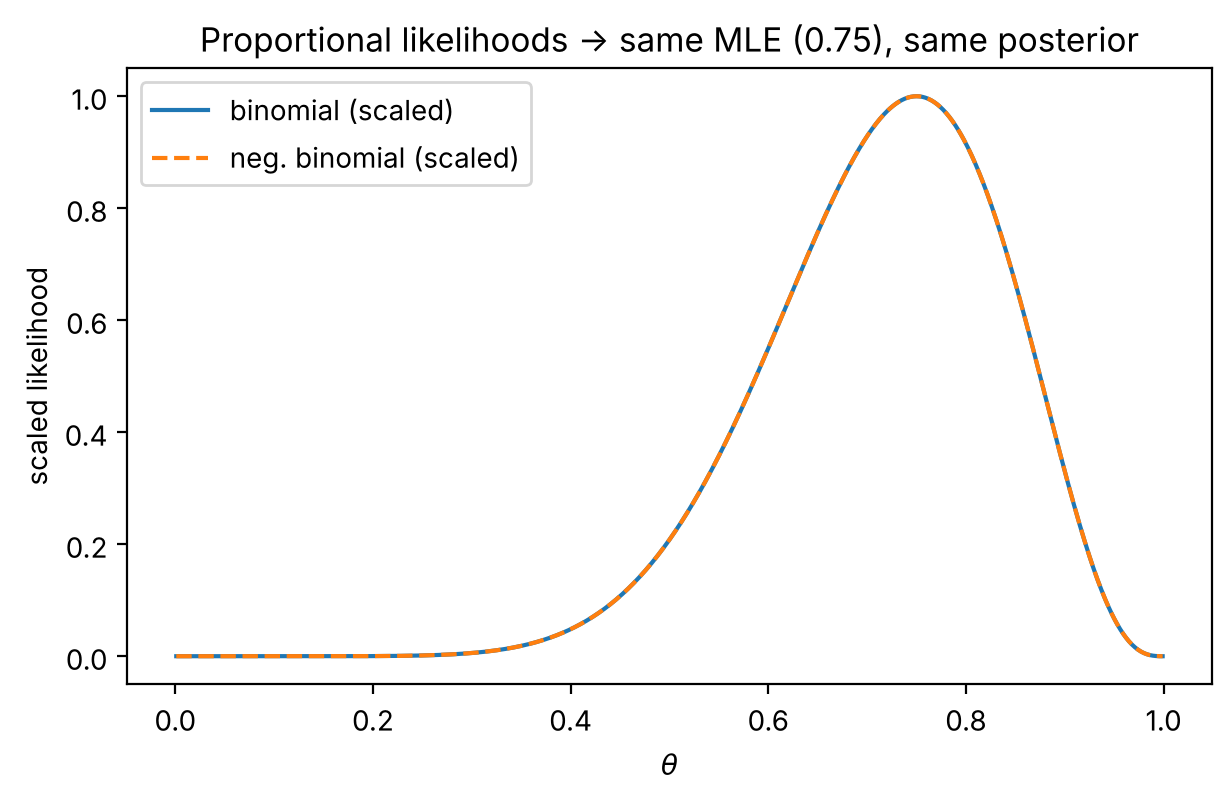

MLE (both): 0.75 0.75


In [5]:
grid = np.linspace(0.001, 0.999, 999)
L1 = stats.binom.pmf(9, 12, grid)
L2 = stats.nbinom.pmf(9, 3, 1 - grid)   # 성공 9번 before 실패 3번 (실패확률 = 1-θ)
plt.plot(grid, L1 / L1.max(), label="binomial (scaled)")
plt.plot(grid, L2 / L2.max(), "--", label="neg. binomial (scaled)")
plt.xlabel(r"$\theta$"); plt.ylabel("scaled likelihood"); plt.legend()
plt.title("Proportional likelihoods -> same MLE (0.75), same posterior")
plt.show()
print("MLE (both):", grid[L1.argmax()].round(3), grid[L2.argmax()].round(3))

## 3. 약한 조건부원리: n=2 또는 n=1000

In [6]:
var_marginal = 0.5 * (1/2) + 0.5 * (1/1000)
print(f"unconditional SE of X̄       : {np.sqrt(var_marginal):.3f}")
print(f"SE given n = 1000 was used  : {np.sqrt(1/1000):.3f}")

unconditional SE of X̄       : 0.500
SE given n = 1000 was used  : 0.032


## 4. 신용구간: 분위수 구간 vs HPD

$X\mid\theta\sim B(10,\theta)$, $\theta\sim Unif(0,1)$, $x=2$ → $\theta\mid x\sim Beta(3,9)$. HPD를 세 가지 방법으로 구해서 비교했다.

In [7]:
post = stats.beta(3, 9)
alpha = 0.05

# (0) 분위수 기반 구간
q_int = post.ppf([alpha/2, 1 - alpha/2])

# (1) 정확한 HPD: 폭이 최소가 되는 하한 분위수 찾기
from scipy.optimize import minimize_scalar
width = lambda p: post.ppf(p + 1 - alpha) - post.ppf(p)
p_opt = minimize_scalar(width, bounds=(0, alpha), method="bounded").x
hpd_exact = post.ppf([p_opt, p_opt + 1 - alpha])

# (2) 그리드 탐색
def hpd_grid(log_unnorm_post, grid, alpha=0.05):
    w = np.exp(log_unnorm_post(grid) - log_unnorm_post(grid).max())
    w = w / w.sum()
    order = np.argsort(w)[::-1]
    M = np.searchsorted(np.cumsum(w[order]), 1 - alpha) + 1
    kept = grid[order[:M]]
    return kept.min(), kept.max()

g = np.linspace(1e-6, 1 - 1e-6, 20_001)
hpd_g = hpd_grid(lambda t: 2*np.log(t) + 8*np.log(1 - t), g)   # θ^2 (1-θ)^8 커널

# (3) 사후표본 기반: 95%를 담는 구간 중 가장 짧은 것
def hpd_sample(samples, alpha=0.05):
    s = np.sort(samples)
    k = int(np.floor((1 - alpha) * len(s)))
    widths = s[k:] - s[:len(s) - k]
    i = widths.argmin()
    return s[i], s[i + k]

hpd_s = hpd_sample(post.rvs(100_000, random_state=rng))

for name, (l, u) in [("quantile", q_int), ("HPD exact", hpd_exact),
                     ("HPD grid", hpd_g), ("HPD sample", hpd_s)]:
    print(f"{name:11s}: ({l:.3f}, {u:.3f})  width = {u - l:.3f}")

quantile   : (0.060, 0.518)  width = 0.458
HPD exact  : (0.041, 0.484)  width = 0.443
HPD grid   : (0.041, 0.484)  width = 0.443
HPD sample : (0.041, 0.486)  width = 0.445


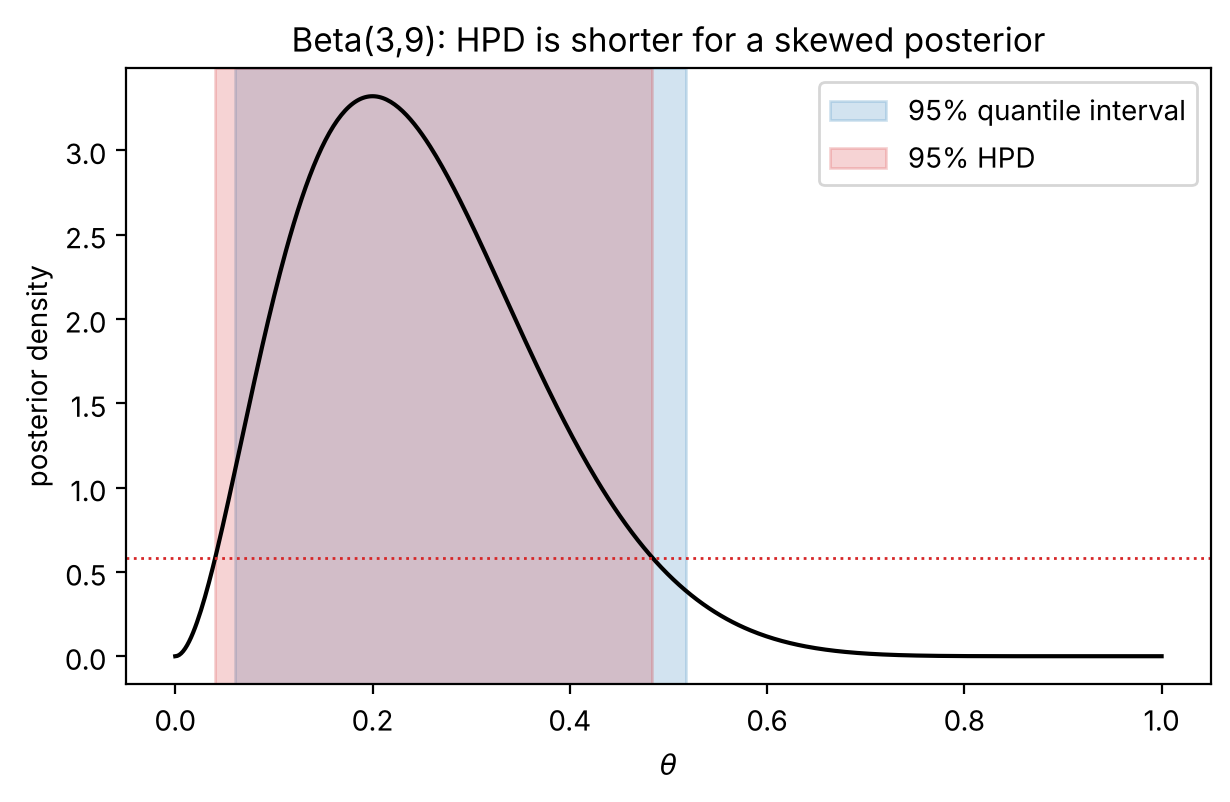

In [8]:
t = np.linspace(0, 1, 500)
plt.plot(t, post.pdf(t), "k")
plt.axvspan(*q_int, alpha=0.2, color="tab:blue", label="95% quantile interval")
plt.axvspan(*hpd_exact, alpha=0.2, color="tab:red", label="95% HPD")
plt.axhline(post.pdf(hpd_exact[0]), ls=":", c="tab:red", lw=1)
plt.xlabel(r"$\theta$"); plt.ylabel("posterior density"); plt.legend()
plt.title("Beta(3,9): HPD is shorter for a skewed posterior")
plt.show()

점선이 HPD를 정하는 수평선 $k$이다. 비대칭 분포라서 분위수 구간은 오른쪽 꼬리를 너무 많이 포함하고, HPD는 밀도가 높은 왼쪽으로 이동한다.

### 다봉 사후분포에서는?

두 정규분포를 섞은 사후분포에서는 HPD 집합이 두 조각으로 끊어진다. 그리드 방법으로 확인.

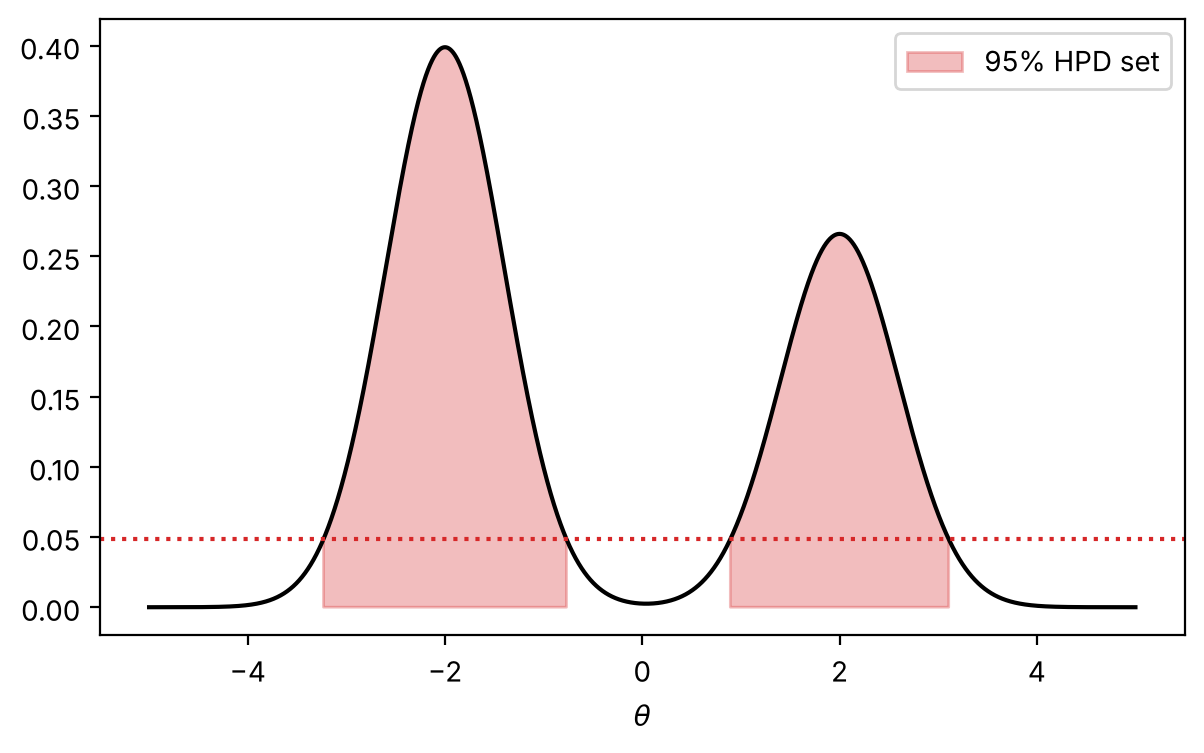

HPD set boundaries: [-3.23 -0.77  0.89  3.11]


In [9]:
mix = lambda t: 0.6 * stats.norm.pdf(t, -2, 0.6) + 0.4 * stats.norm.pdf(t, 2, 0.6)
g = np.linspace(-5, 5, 20_001)
w = mix(g) / mix(g).sum()
order = np.argsort(w)[::-1]
M = np.searchsorted(np.cumsum(w[order]), 0.95) + 1
k = w[order[M - 1]] / (g[1] - g[0])     # 밀도 스케일의 k
inside = mix(g) >= k
plt.plot(g, mix(g), "k")
plt.fill_between(g, 0, mix(g), where=inside, alpha=0.3, color="tab:red", label="95% HPD set")
plt.axhline(k, ls=":", c="tab:red")
plt.legend(); plt.xlabel(r"$\theta$"); plt.show()
edges = g[np.flatnonzero(np.diff(inside.astype(int)) != 0)]
print("HPD set boundaries:", edges.round(2))